# AC2 — Reconhecimento de Padrões: Qualidade de Vinho Tinto

**Disciplina:** Reconhecimento de Padrões e Aprendizado de Máquina

**Aluno:** Giovanne Vieira de Queiroz. 235969. TIN3.

**Dataset:** [Wine Quality — UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/datasets/wine+quality) — 1.599 vinhos tintos portugueses da região do Vinho Verde

Este trabalho usa resultados de testes químicos de vinhos tintos para responder a três perguntas, nas quatro etapas da prova:

1. **Preparação dos dados:** como organizar e padronizar as informações (Etapa 1);
2. **Agrupamento sem rótulos:** vinhos com química parecida formam grupos naturais? Esses grupos têm a ver com a nota de qualidade? (Etapa 2);
3. **Classificação:** é possível prever se um vinho é `bom` ou `ruim` a partir da química, usando KNN, Árvore de Decisão (Etapa 3) e rede neural MLP (Etapa 4)?

**Como executar:** rode as células de cima a baixo (Kernel → Restart and Run All).

## Dicionário das variáveis

| Variável | O que mede |
|---|---|
| `fixed acidity` | Acidez fixa — ácidos que não evaporam (g/L) |
| `volatile acidity` | Acidez volátil — em excesso lembra vinagre (g/L) |
| `citric acid` | Ácido cítrico — dá frescor ao vinho (g/L) |
| `residual sugar` | Açúcar restante após a fermentação (g/L) |
| `chlorides` | Cloretos — sensação de salinidade (g/L) |
| `free sulfur dioxide` | Dióxido de enxofre livre — conservante (mg/L) |
| `total sulfur dioxide` | Dióxido de enxofre total (mg/L) |
| `density` | Densidade (g/cm³) |
| `pH` | Acidez na escala pH (0 muito ácido a 14 muito básico) |
| `sulphates` | Sulfatos — ajudam na conservação (g/L) |
| `alcohol` | Teor alcoólico (% em volume) |
| `quality` | Nota de 0 a 10 dada por degustadores — **variável alvo** |

In [28]:
# Bibliotecas
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc, silhouette_score,
)

# Configurações gerais: mesma semente para resultados reproduzíveis
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

print("Setup concluído.")

Setup concluído.


---

## ETAPA 1 — Carregamento de Dados e Pré-processamento (2,5 pontos)

> **Questão 1.1:** Carregue o dataset de vinhos tintos diretamente da URL pública. Trate eventuais inconsistências, separe as variáveis preditoras (X) do alvo (y — coluna `quality` convertida em classificação binária: 'bom' se qualidade >= 6, senão 'ruim') e aplique normalização utilizando `StandardScaler`.

In [29]:
# Carga dos dados: primeiro tentamos a URL pública; se não houver internet,
# usamos a cópia local salva em ../data/ (arquivos separados por ';')
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
LOCAL = "../data/winequality-red.csv"

try:
    df = pd.read_csv(URL, sep=";")
    print(f"Dados carregados da URL pública ({len(df)} vinhos).")
except Exception:
    df = pd.read_csv(LOCAL, sep=";")
    print(f"URL indisponível — dados carregados da cópia local ({len(df)} vinhos).")

df.head()

Dados carregados da URL pública (1599 vinhos).


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [30]:
# Verificação de consistência: dimensões, faltantes, duplicatas e faixas de valores
print(f"Dimensões: {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"Valores faltantes: {df.isnull().sum().sum()}")
print(f"Linhas duplicadas: {df.duplicated().sum()}")
print(f"Notas de qualidade encontradas: {sorted(df['quality'].unique())}")

df.describe().round(2)

Dimensões: 1599 linhas x 12 colunas
Valores faltantes: 0
Linhas duplicadas: 240
Notas de qualidade encontradas: [3, 4, 5, 6, 7, 8]


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00
mean,8.32,0.53,0.27,2.54,0.09,15.87,46.47,1.00,3.31,0.66,10.42,5.64
std,1.74,0.18,0.19,1.41,0.05,10.46,32.90,0.00,0.15,0.17,1.07,0.81
min,4.60,0.12,0.00,0.90,0.01,1.00,6.00,0.99,2.74,0.33,8.40,3.00
25%,7.10,0.39,0.09,1.90,0.07,7.00,22.00,1.00,3.21,0.55,9.50,5.00
50%,7.90,0.52,0.26,2.20,0.08,14.00,38.00,1.00,3.31,0.62,10.20,6.00
75%,9.20,0.64,0.42,2.60,0.09,21.00,62.00,1.00,3.40,0.73,11.10,6.00
max,15.90,1.58,1.00,15.50,0.61,72.00,289.00,1.00,4.01,2.00,14.90,8.00


**Leitura:** não há valores faltantes e todas as variáveis estão dentro de faixas fisicamente possíveis — o dataset não exige correções. As 240 linhas duplicadas são vinhos com perfil químico idêntico; como são registros reais e plausíveis, elas foram mantidas (remover seria descartar informação).

In [31]:
# Conversão do alvo em duas classes: 'bom' (nota >= 6) e 'ruim' (nota < 6)
df["classe"] = np.where(df["quality"] >= 6, "bom", "ruim")

X = df.drop(columns=["quality", "classe"])  # variáveis preditoras (11 colunas)
y = df["classe"]                            # alvo binário

pd.crosstab(df["quality"], df["classe"], margins=True)

classe,bom,ruim,All
quality,,,
3,0,10,10
4,0,53,53
5,0,681,681
6,638,0,638
7,199,0,199
8,18,0,18
All,855,744,1599


**Leitura:** a regra pedida (nota ≥ 6 = `bom`) gera 855 vinhos bons (53,5%) e 744 ruins (46,5%). As classes ficam equilibradas, o que facilita o trabalho dos modelos e a leitura das métricas.

In [32]:
# Normalização com StandardScaler: cada variável passa a ter média 0 e desvio padrão 1.
# Isso é necessário porque K-Means, KNN e MLP dependem de distâncias/gradientes,
# e sem isso variáveis em escala maior (ex.: 'total sulfur dioxide') dominariam as menores.
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)

X_scaled.describe().round(3).loc[["mean", "std", "min", "max"]]

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
mean,0.000,0.000,-0.000,-0.000,0.000,-0.000,0.000,-0.000,0.000,0.000,0.000
std,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
min,-2.137,-2.278,-1.391,-1.163,-1.604,-1.423,-1.231,-3.539,-3.700,-1.937,-1.899
max,4.355,5.878,3.744,9.196,11.127,5.367,7.375,3.680,4.528,7.919,4.202


**Leitura:** após a normalização, todas as 11 variáveis têm média 0 e desvio padrão 1. Esta versão completa será usada na **Etapa 2** (K-Means). Nos classificadores (Etapas 3 e 4), o normalizador será reajustado usando **apenas o treino**, para o teste não influenciar o aprendizado.

---

## Análise Exploratória dos Dados

Antes de treinar os modelos, vale conhecer os dados: como as classes se distribuem, como cada variável se comporta e que relações existem entre elas.

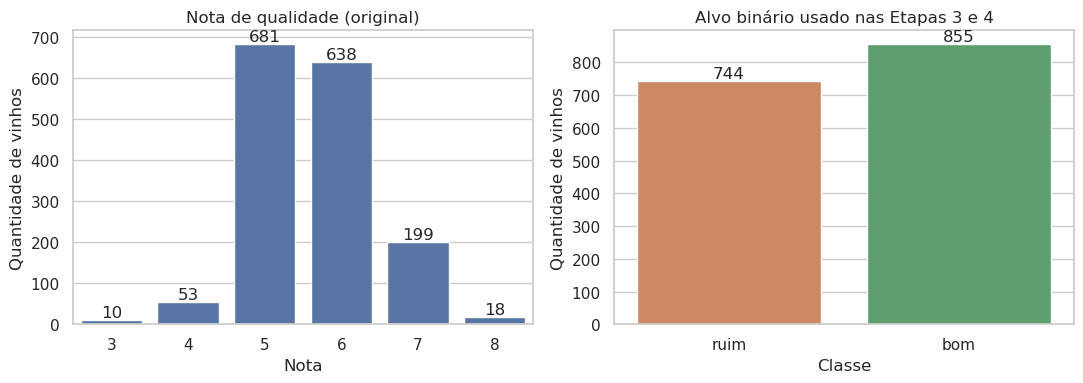

In [33]:
# Distribuição da nota original e do alvo binário
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.countplot(x="quality", data=df, color="#4c72b0", ax=axes[0])
axes[0].set_title("Nota de qualidade (original)")
axes[0].set_xlabel("Nota")
axes[0].set_ylabel("Quantidade de vinhos")

sns.countplot(x="classe", data=df, order=["ruim", "bom"], hue="classe",
              palette={"ruim": "#dd8452", "bom": "#55a868"}, legend=False, ax=axes[1])
axes[1].set_title("Alvo binário usado nas Etapas 3 e 4")
axes[1].set_xlabel("Classe")
axes[1].set_ylabel("Quantidade de vinhos")

for ax in axes:
    for container in ax.containers:
        ax.bar_label(container)

plt.tight_layout()
plt.show()

**Leitura:** as notas 5 e 6 concentram a maioria absoluta dos vinhos — vinhos medianos são a norma, e extremos são raros. Depois da conversão em duas classes, o equilíbrio fica bom (53,5% x 46,5%), então não precisaremos de técnicas para corrigir desbalanceamento.

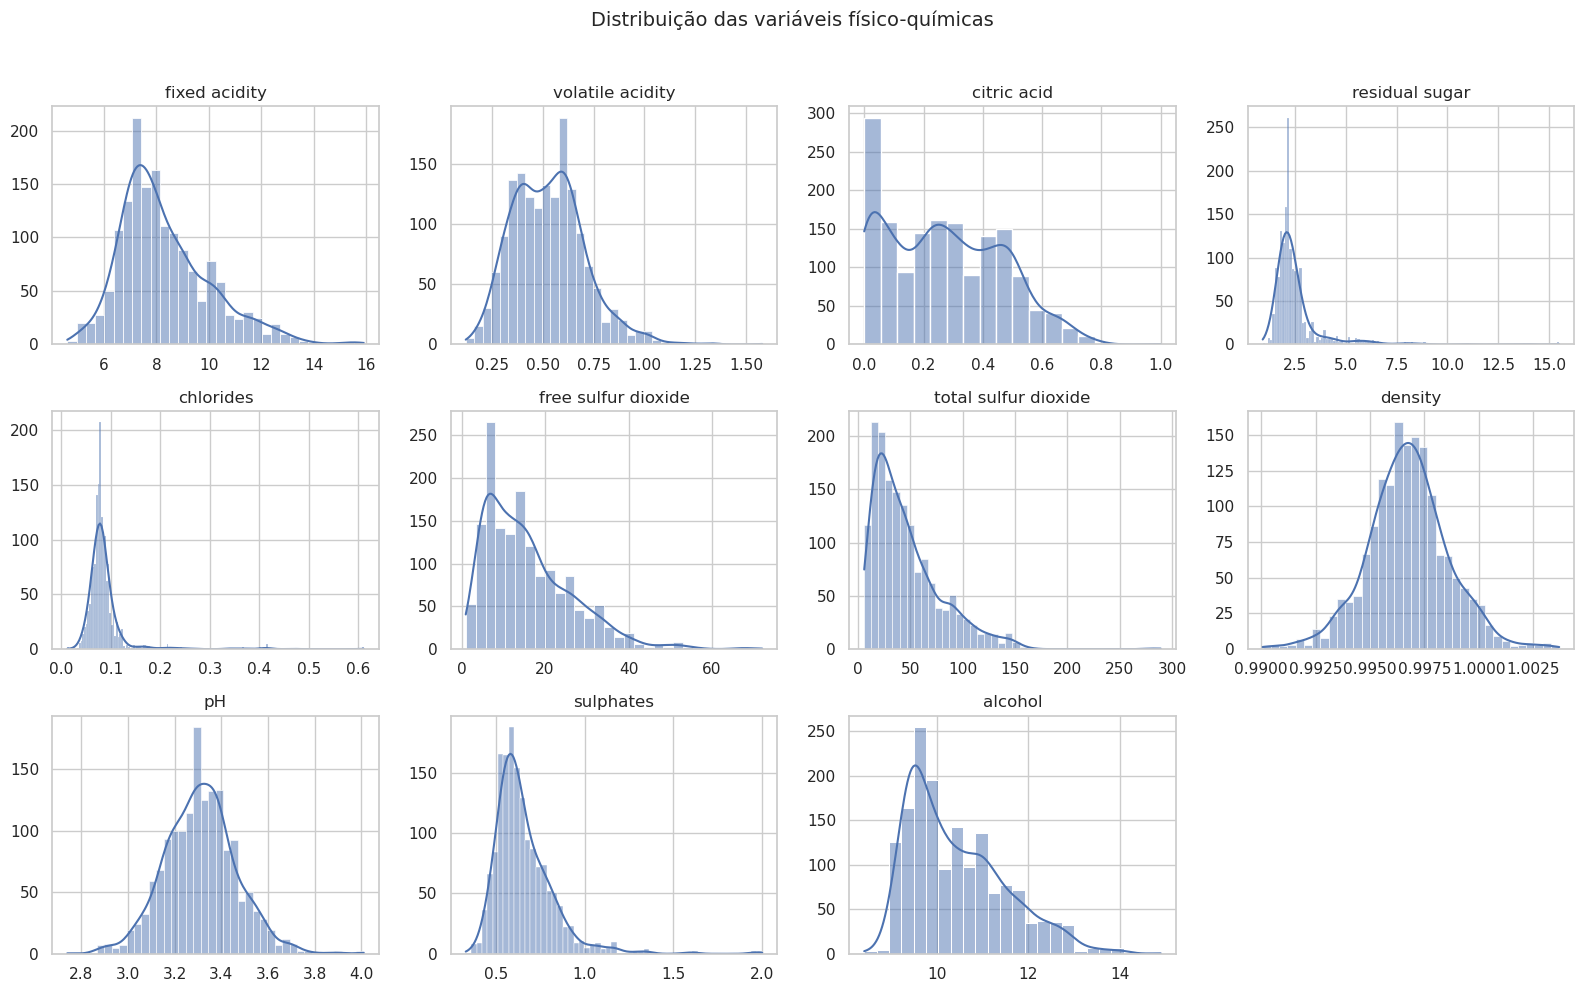

In [34]:
# Histogramas das 11 variáveis preditoras
variaveis = [c for c in df.columns if c not in ("quality", "classe")]

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, var in zip(axes.flat, variaveis):
    sns.histplot(df[var], kde=True, color="#4c72b0", ax=ax)
    ax.set_title(var)
    ax.set_xlabel("")
    ax.set_ylabel("")
axes.flat[-1].axis("off")

fig.suptitle("Distribuição das variáveis físico-químicas", y=0.99, fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

**Leitura:** várias variáveis têm formato parecido com um "sino" (comportamento normal), como `density`, `pH` e `alcohol`. Outras ficam concentradas à esquerda com uma cauda longa à direita, como `residual sugar` e os dióxidos de enxofre: a maioria dos vinhos tem valores baixos e poucos têm valores muito altos. Esses valores extremos justificam o uso da normalização na Etapa 1.

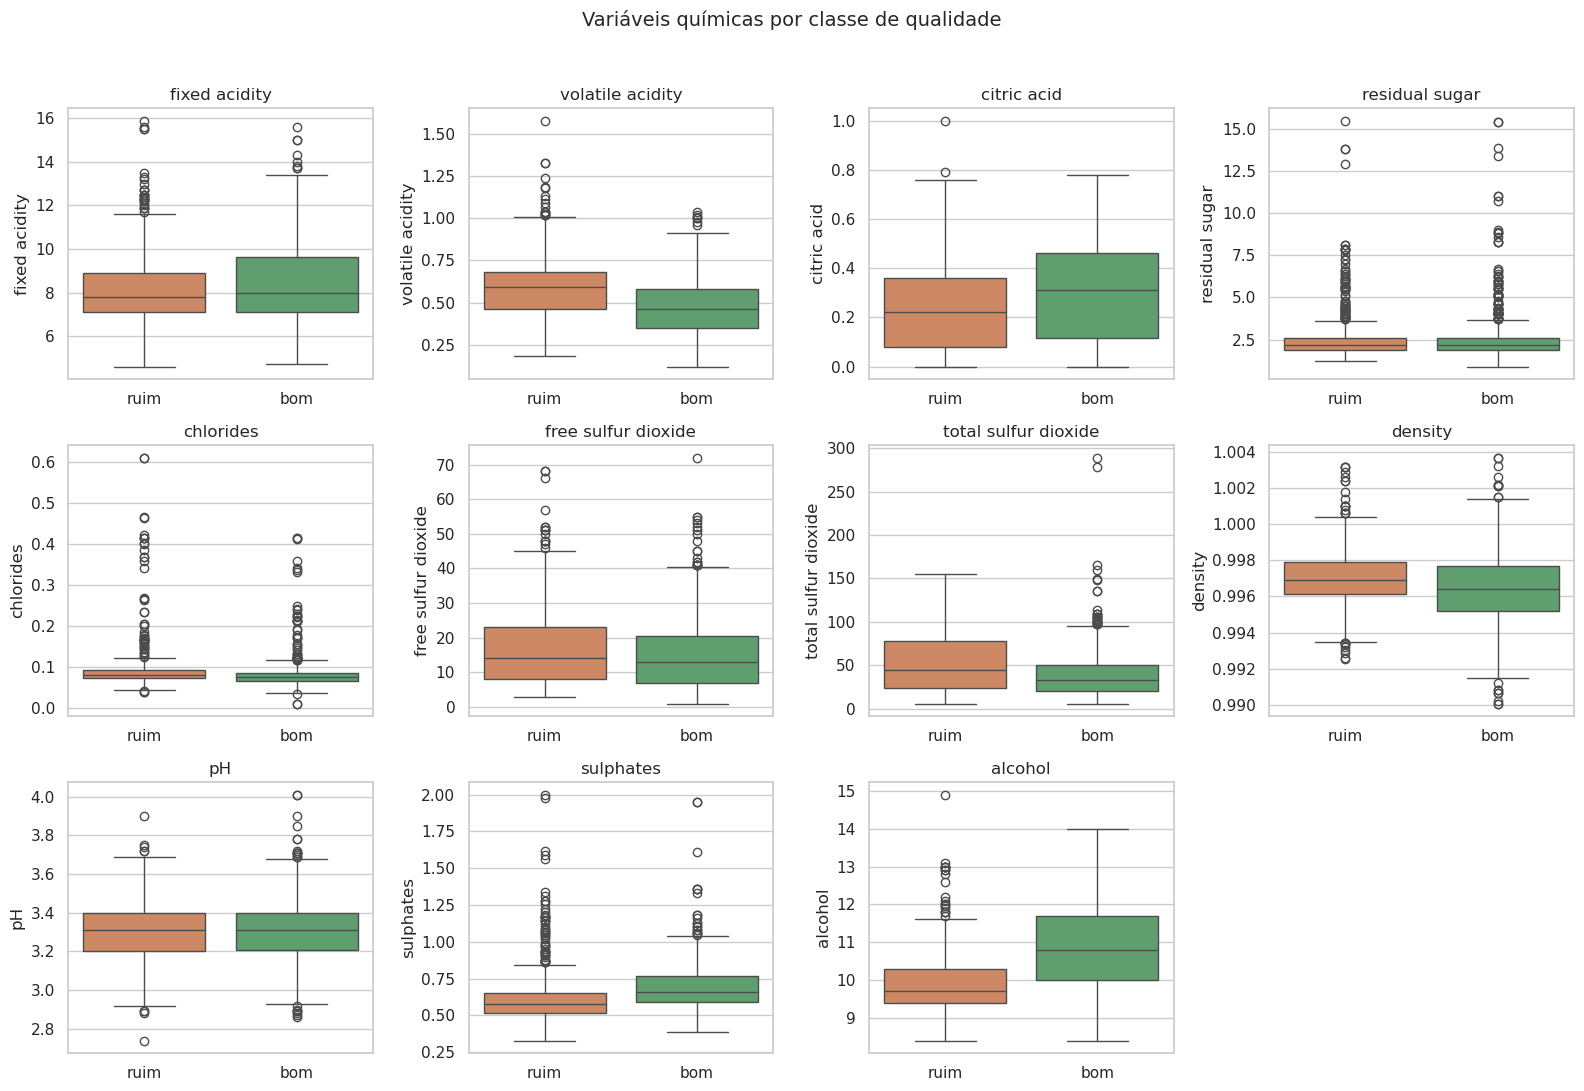

In [35]:
# Boxplots: compara cada variável entre vinhos ruins e bons
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
for ax, var in zip(axes.flat, variaveis):
    sns.boxplot(data=df, x="classe", y=var, order=["ruim", "bom"], hue="classe",
                palette={"ruim": "#dd8452", "bom": "#55a868"}, legend=False, dodge=False, ax=ax)
    ax.set_title(var)
    ax.set_xlabel("")
axes.flat[-1].axis("off")

fig.suptitle("Variáveis químicas por classe de qualidade", y=0.99, fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

**Leitura:** vinhos bons se diferenciam principalmente em três pontos: têm **mais álcool**, **menos acidez volátil** (a que lembra vinagre) e **mais sulfatos**. Nos boxplots dessas variáveis, as caixas das duas classes ficam mais separadas; nas outras, elas se sobrepõem bastante. São indícios de quais variáveis devem pesar mais na classificação.

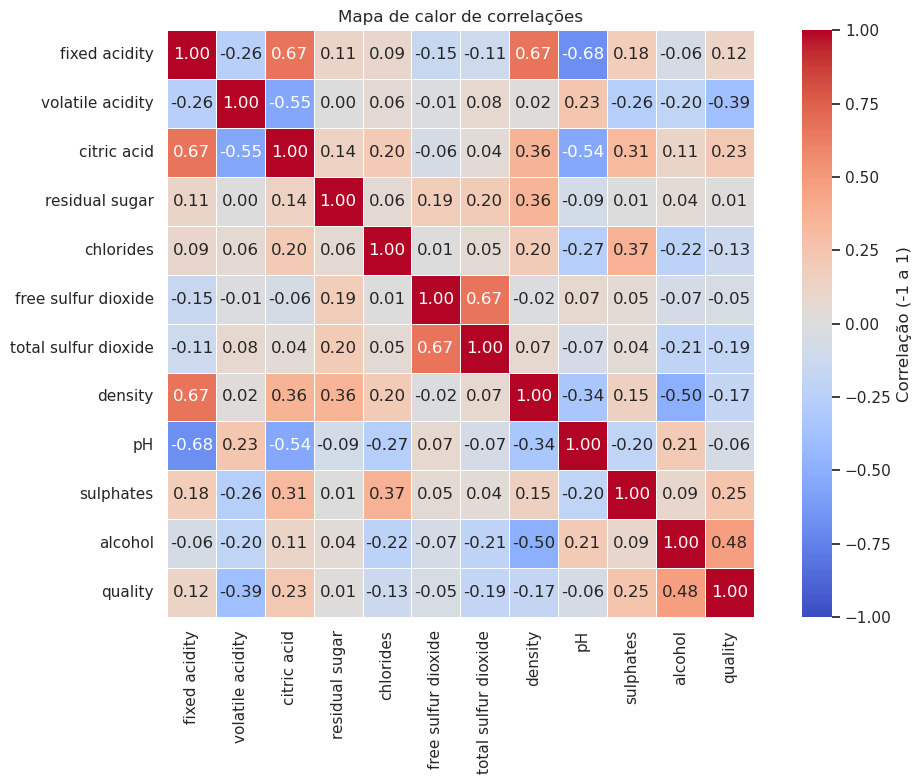

In [36]:
# Correlação entre todas as variáveis, incluindo a qualidade
plt.figure(figsize=(11, 8))
corr = df.drop(columns="classe").corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"label": "Correlação (-1 a 1)"})
plt.title("Mapa de calor de correlações")
plt.tight_layout()
plt.show()

**Leitura:** com a qualidade, as correlações mais fortes são **álcool (+0,48)** e **acidez volátil (−0,39)** — confirmam o que os boxplots mostraram. Também há pares de variáveis muito correlacionadas entre si, como `fixed acidity` x `density` (+0,67) e `free` x `total sulfur dioxide` (+0,67): algumas carregam informação repetida. Como o número de variáveis é pequeno (11), mantivemos todas nos modelos.

---

## ETAPA 2 — Aprendizado Não Supervisionado: K-Means (2,5 pontos)

> **Questão 2.1:** Desconsidere os rótulos de qualidade por um momento. Aplique o algoritmo K-Means para encontrar agrupamentos naturais nos dados normalizados. Use o método do Cotovelo (Elbow Method) ou Silhouette Score para justificar a escolha do número ideal de clusters (K) entre 2 e 5. Plote os resultados.

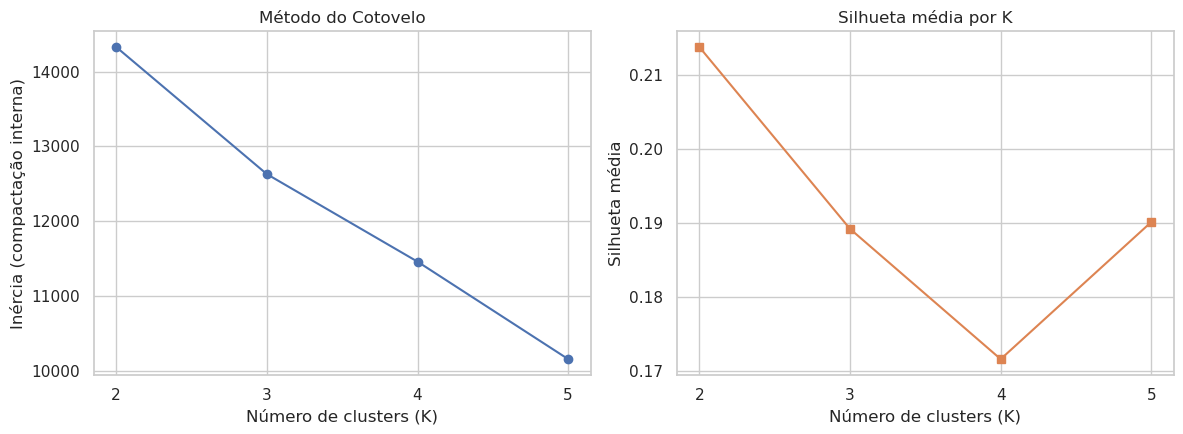

,K,Inércia,Silhueta
0,2,14330.1,0.214
1,3,12630.0,0.189
2,4,11459.1,0.172
3,5,10155.5,0.190


In [37]:
# Testa K de 2 a 5 com dois critérios:
# - Cotovelo: a inércia mede quão "apertados" são os clusters (menor = melhor);
#   o K ideal fica no "cotovelo" da curva, onde parar de cair rápido.
# - Silhueta: mede quão bem cada vinho está no seu cluster (de -1 a 1; maior = melhor).
faixa_k = range(2, 6)
inercias, silhuetas = [], []

for k in faixa_k:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    etiquetas = km.fit_predict(X_scaled)
    inercias.append(km.inertia_)
    silhuetas.append(silhouette_score(X_scaled, etiquetas))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(faixa_k, inercias, marker="o", color="#4c72b0")
axes[0].set_title("Método do Cotovelo")
axes[0].set_xlabel("Número de clusters (K)")
axes[0].set_ylabel("Inércia (compactação interna)")
axes[0].set_xticks(faixa_k)

axes[1].plot(faixa_k, silhuetas, marker="s", color="#dd8452")
axes[1].set_title("Silhueta média por K")
axes[1].set_xlabel("Número de clusters (K)")
axes[1].set_ylabel("Silhueta média")
axes[1].set_xticks(faixa_k)

plt.tight_layout()
plt.show()

pd.DataFrame({"K": faixa_k, "Inércia": np.round(inercias, 1), "Silhueta": np.round(silhuetas, 3)})

**Leitura e escolha do K:** a maior queda da inércia acontece de K=2 para K=3 — depois a curva desacelera (o "cotovelo" está em K=2 ou K=3). A silhueta desempata: ela é máxima justamente em **K=2** (0,21, contra 0,19 de K=3). Com os dois critérios apontando para o mesmo lado, **escolhemos K=2**. Por coincidência interessante, é o mesmo número de classes reais (bom/ruim).

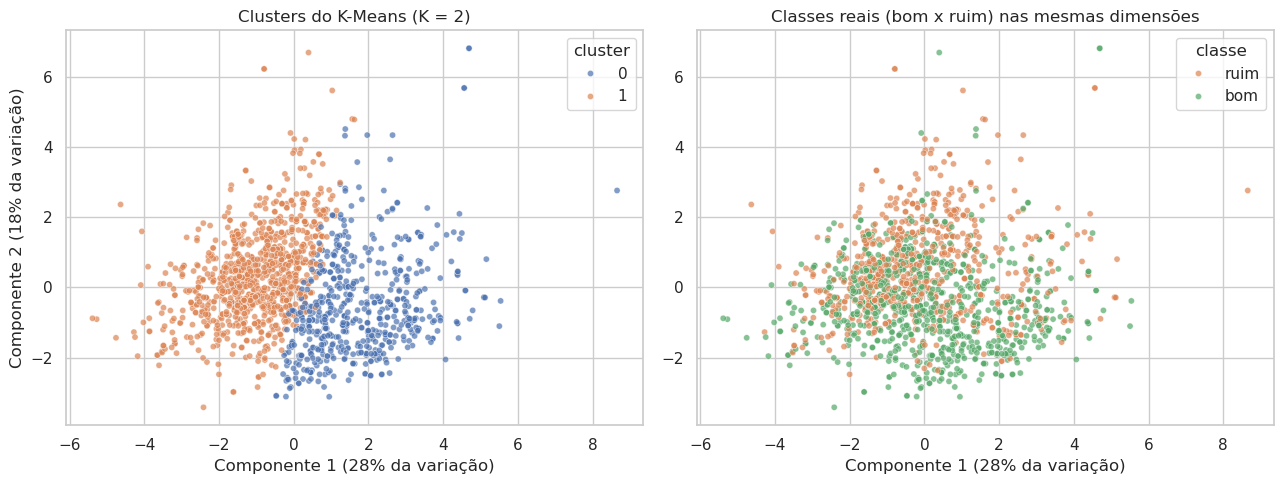

In [38]:
# K-Means final com K=2, usando os dados normalizados (sem os rótulos)
km_final = KMeans(n_clusters=2, random_state=RANDOM_STATE, n_init=10)
df["cluster"] = km_final.fit_predict(X_scaled)

# Redução para 2 dimensões apenas para visualização (PCA resume as 11 variáveis
# mantendo o máximo possível da variação original)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df["cluster"], palette="deep",
                s=20, alpha=0.7, ax=axes[0])
axes[0].set_title("Clusters do K-Means (K = 2)")
axes[0].set_xlabel(f"Componente 1 ({pca.explained_variance_ratio_[0]:.0%} da variação)")
axes[0].set_ylabel(f"Componente 2 ({pca.explained_variance_ratio_[1]:.0%} da variação)")

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df["classe"], hue_order=["ruim", "bom"],
                palette={"ruim": "#dd8452", "bom": "#55a868"}, s=20, alpha=0.7, ax=axes[1])
axes[1].set_title("Classes reais (bom x ruim) nas mesmas dimensões")
axes[1].set_xlabel(f"Componente 1 ({pca.explained_variance_ratio_[0]:.0%} da variação)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**Leitura:** à esquerda, os clusters encontrados sem conhecer nenhuma nota; à direita, as classes reais nas mesmas coordenadas. Os grupos do K-Means são compactos, mas as cores da direita aparecem misturadas — a separação química não coincide com a fronteira bom/ruim. É um primeiro sinal de que o problema não é linearmente separável.

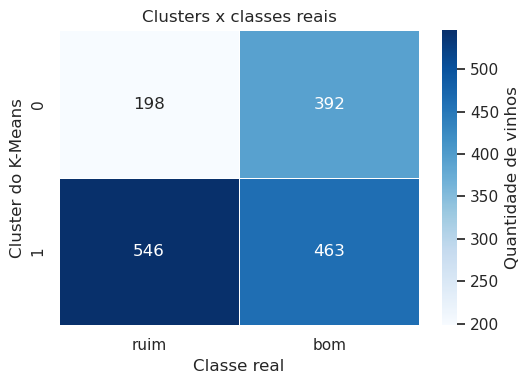

Acordo entre clusters e classes reais: 58.7%


In [39]:
# Cruzamento entre clusters e classes reais
tabela_cluster = pd.crosstab(df["cluster"], df["classe"])[["ruim", "bom"]]

# Se cada cluster "virar" a classe mais frequente dentro dele, qual é o acordo?
classe_do_cluster = tabela_cluster.idxmax(axis=1)
acordo = (df["cluster"].map(classe_do_cluster) == df["classe"]).mean()

plt.figure(figsize=(5.5, 4))
sns.heatmap(tabela_cluster, annot=True, fmt="d", cmap="Blues", linewidths=0.5,
            cbar_kws={"label": "Quantidade de vinhos"})
plt.title("Clusters x classes reais")
plt.xlabel("Classe real")
plt.ylabel("Cluster do K-Means")
plt.tight_layout()
plt.show()

print(f"Acordo entre clusters e classes reais: {acordo:.1%}")

**Leitura:** o cluster 0 reúne mais vinhos **bons** (392 bons x 198 ruins) e o cluster 1 mais vinhos **ruins** (546 x 463). O acordo total é de **58,7%**: o agrupamento captura parte do sinal de qualidade, mas com muita mistura — provavelmente porque os grupos se formam pela química geral (ex.: dióxido de enxofre e açúcar), e não pela nota. Sem um "professor" que mostre as notas, o K-Means não consegue recuperar sozinho a fronteira entre bom e ruim. Isso motiva os métodos supervisionados das próximas etapas.

---

## ETAPA 3 — Aprendizado Supervisionado Clássico: KNN e Árvore de Decisão (2,5 pontos)

> **Questão 3.1:** Divida o dataset original em treino e teste (80/20). Treine um classificador KNN e um classificador de Árvore de Decisão. Compare o desempenho de ambos usando métricas apropriadas (Acurácia, Precisão, Recall e Matriz de Confusão).

In [40]:
# Divisão treino/teste 80/20 estratificada: a proporção bom/ruim se mantém nas duas partes
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

# Boa prática contra vazamento de dados: o normalizador é ajustado APENAS com o treino
# e depois aplicado ao teste. Assim o teste simula vinhos nunca vistos antes.
scaler_treino = StandardScaler()
X_train_scaled = scaler_treino.fit_transform(X_train)
X_test_scaled = scaler_treino.transform(X_test)

print(f"Treino: {X_train.shape[0]} vinhos | Teste: {X_test.shape[0]} vinhos")
print(f"Proporção de 'bom' no treino: {(y_train == 'bom').mean():.1%}")
print(f"Proporção de 'bom' no teste:  {(y_test == 'bom').mean():.1%}")

Treino: 1279 vinhos | Teste: 320 vinhos
Proporção de 'bom' no treino: 53.5%
Proporção de 'bom' no teste:  53.4%


**Leitura:** 1.279 vinhos para treinar e 320 para testar, com a mesma proporção de classes nas duas partes (estratificação). O normalizador foi reajustado usando só o treino — versão mais rigorosa do que escalar tudo de uma vez, pois o teste continua sendo uma simulação honesta de vinhos novos.

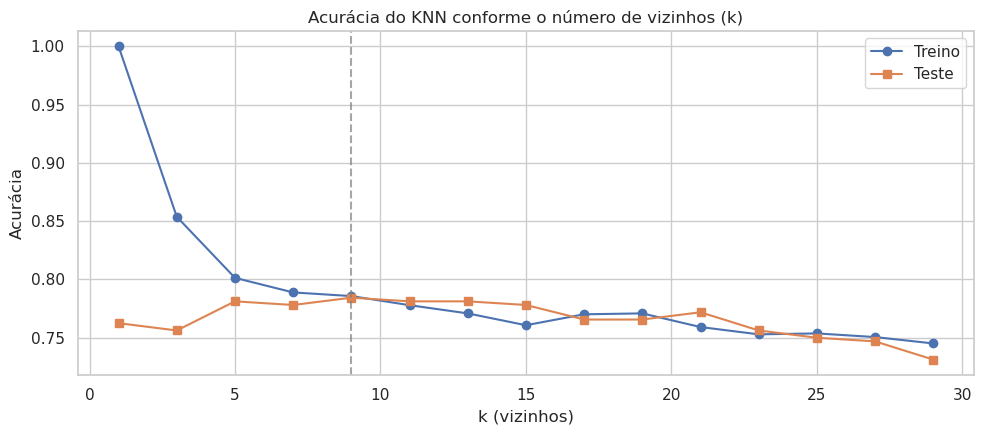

Melhor k no teste: 9 (acurácia 78.4%)


In [41]:
# Escolha do k do KNN: testamos valores ímpares de 1 a 29
ks = list(range(1, 30, 2))
acc_treino_knn, acc_teste_knn = [], []

for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    acc_treino_knn.append(knn.score(X_train_scaled, y_train))
    acc_teste_knn.append(knn.score(X_test_scaled, y_test))

plt.figure(figsize=(10, 4.5))
plt.plot(ks, acc_treino_knn, marker="o", label="Treino", color="#4c72b0")
plt.plot(ks, acc_teste_knn, marker="s", label="Teste", color="#dd8452")
plt.axvline(ks[int(np.argmax(acc_teste_knn))], linestyle="--", color="gray", alpha=0.7)
plt.title("Acurácia do KNN conforme o número de vizinhos (k)")
plt.xlabel("k (vizinhos)")
plt.ylabel("Acurácia")
plt.legend()
plt.tight_layout()
plt.show()

melhor_k = ks[int(np.argmax(acc_teste_knn))]
print(f"Melhor k no teste: {melhor_k} (acurácia {max(acc_teste_knn):.1%})")

**Leitura:** com k muito pequeno (1, 3), o modelo "decora" o treino — acurácia de treino alta e teste mais baixo. A partir de k por volta de 10, o teste estabiliza. A linha tracejada marca o melhor k no teste, usado daqui em diante.

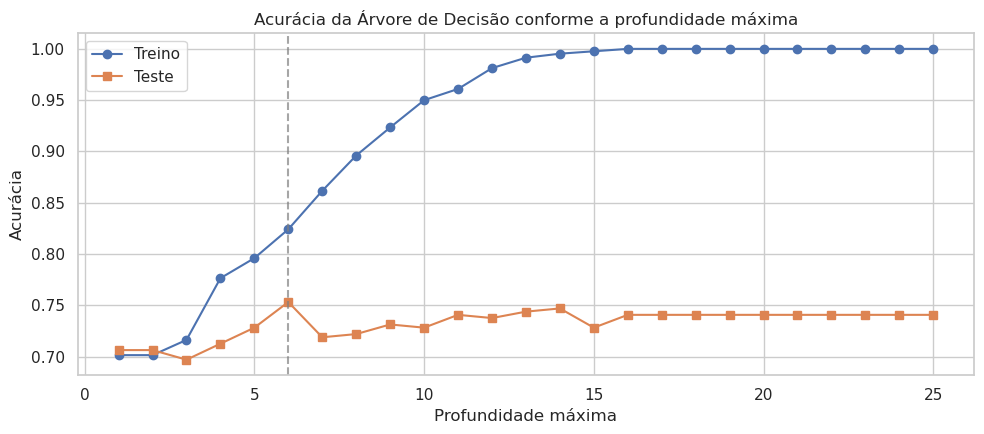

Melhor profundidade no teste: 6 (acurácia 75.3%)


In [43]:
# Escolha da profundidade máxima da Árvore de Decisão
profundidades = list(range(1, 26))
acc_treino_arv, acc_teste_arv = [], []

for prof in profundidades:
    arv = DecisionTreeClassifier(max_depth=prof, random_state=RANDOM_STATE)
    arv.fit(X_train_scaled, y_train)
    acc_treino_arv.append(arv.score(X_train_scaled, y_train))
    acc_teste_arv.append(arv.score(X_test_scaled, y_test))

plt.figure(figsize=(10, 4.5))
plt.plot(profundidades, acc_treino_arv, marker="o", label="Treino", color="#4c72b0")
plt.plot(profundidades, acc_teste_arv, marker="s", label="Teste", color="#dd8452")
plt.axvline(profundidades[int(np.argmax(acc_teste_arv))], linestyle="--", color="gray", alpha=0.7)
plt.title("Acurácia da Árvore de Decisão conforme a profundidade máxima")
plt.xlabel("Profundidade máxima")
plt.ylabel("Acurácia")
plt.legend()
plt.tight_layout()
plt.show()

melhor_prof = profundidades[int(np.argmax(acc_teste_arv))]
print(f"Melhor profundidade no teste: {melhor_prof} (acurácia {max(acc_teste_arv):.1%})")

**Leitura:** a curva azul (treino) sobe até 100% conforme a árvore fica mais funda — ela passa a memorizar os exemplos. A curva laranja (teste) para de crescer antes: a partir dali, mais profundidade só aumenta o sobreajuste (decorar em vez de aprender). A linha tracejada marca a profundidade escolhida.

In [44]:
# Modelos finais com os melhores hiperparâmetros encontrados acima
knn_final = KNeighborsClassifier(n_neighbors=melhor_k)
knn_final.fit(X_train_scaled, y_train)

arv_final = DecisionTreeClassifier(max_depth=melhor_prof, random_state=RANDOM_STATE)
arv_final.fit(X_train_scaled, y_train)

# Métricas no teste (sempre com relação à classe 'bom')
resultados = []
for nome, modelo in [("KNN", knn_final), ("Árvore de Decisão", arv_final)]:
    pred = modelo.predict(X_test_scaled)
    resultados.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_test, pred),
        "Precisão": precision_score(y_test, pred, pos_label="bom"),
        "Recall": recall_score(y_test, pred, pos_label="bom"),
        "F1": f1_score(y_test, pred, pos_label="bom"),
    })

tabela_etapa3 = pd.DataFrame(resultados).set_index("Modelo")
tabela_etapa3.round(4)

,Acurácia,Precisão,Recall,F1
Modelo,,,,
KNN,0.7844,0.7656,0.8596,0.8099
Árvore de Decisão,0.7531,0.7875,0.7368,0.7613


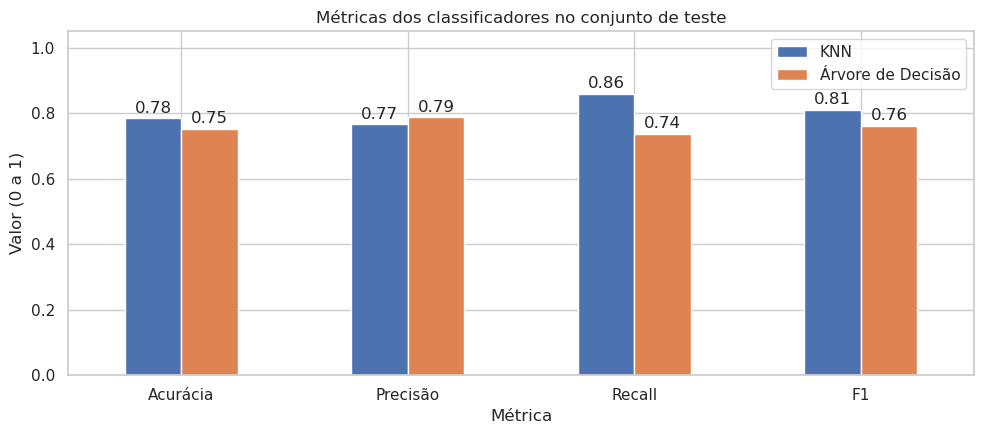

In [45]:
# Mesma tabela em gráfico, para facilitar a comparação
ax = tabela_etapa3.T.plot(kind="bar", figsize=(10, 4.5), rot=0, color=["#4c72b0", "#dd8452"])
ax.set_title("Métricas dos classificadores no conjunto de teste")
ax.set_ylabel("Valor (0 a 1)")
ax.set_xlabel("Métrica")
ax.set_ylim(0, 1.05)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2)
plt.legend(title="")
plt.tight_layout()
plt.show()

**Leitura:** os dois modelos ficam próximos, com vantagem para o **KNN** (acurácia de 78,4% x 75,3%) — a árvore só vence na precisão. Em resumo: **Acurácia** = proporção de acertos no total; **Precisão** (para 'bom') = dos vinhos marcados como bons, quantos eram bons de fato; **Recall** = dos vinhos realmente bons, quantos o modelo encontrou; **F1** = equilíbrio entre precisão e recall.

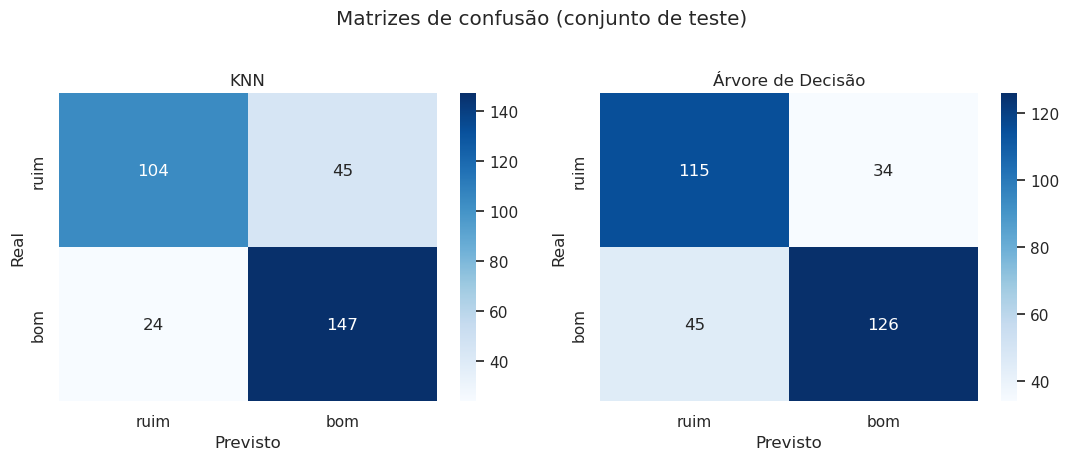

In [46]:
# Matrizes de confusão: onde cada modelo acerta e erra
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (nome, modelo) in zip(axes, [("KNN", knn_final), ("Árvore de Decisão", arv_final)]):
    cm = confusion_matrix(y_test, modelo.predict(X_test_scaled), labels=["ruim", "bom"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["ruim", "bom"], yticklabels=["ruim", "bom"], ax=ax)
    ax.set_title(nome)
    ax.set_xlabel("Previsto")
    ax.set_ylabel("Real")

plt.suptitle("Matrizes de confusão (conjunto de teste)", y=1.02)
plt.tight_layout()
plt.show()

**Leitura:** a diagonal (topo-esquerda a baixo-direita) mostra os acertos; o resto são os erros. Os erros se concentram em vinhos bons classificados como ruins e vice-versa, de forma parecida nos dois modelos — coerente com a sobreposição vista na análise exploratória.

In [47]:
# Relatórios completos (precisão, recall e F1 para cada classe)
for nome, modelo in [("KNN", knn_final), ("Árvore de Decisão", arv_final)]:
    print(f"===== {nome} =====")
    print(classification_report(y_test, modelo.predict(X_test_scaled), labels=["ruim", "bom"]))

===== KNN =====
              precision    recall  f1-score   support

        ruim       0.81      0.70      0.75       149
         bom       0.77      0.86      0.81       171

    accuracy                           0.78       320
   macro avg       0.79      0.78      0.78       320
weighted avg       0.79      0.78      0.78       320

===== Árvore de Decisão =====
              precision    recall  f1-score   support

        ruim       0.72      0.77      0.74       149
         bom       0.79      0.74      0.76       171

    accuracy                           0.75       320
   macro avg       0.75      0.75      0.75       320
weighted avg       0.76      0.75      0.75       320



**Leitura:** os modelos erram de formas diferentes. O KNN tem recall alto para 'bom' (0,86): encontra quase todos os bons, mas para isso marca muitos ruins como bons (precisão 0,77). A árvore é mais conservadora: quando marca um vinho como bom, acerta mais (precisão 0,79), porém deixa escapar mais vinhos bons (recall 0,74). Dependendo do objetivo — não perder bons vinhos ou não elogiar vinhos ruins — um ou outro seria preferível.

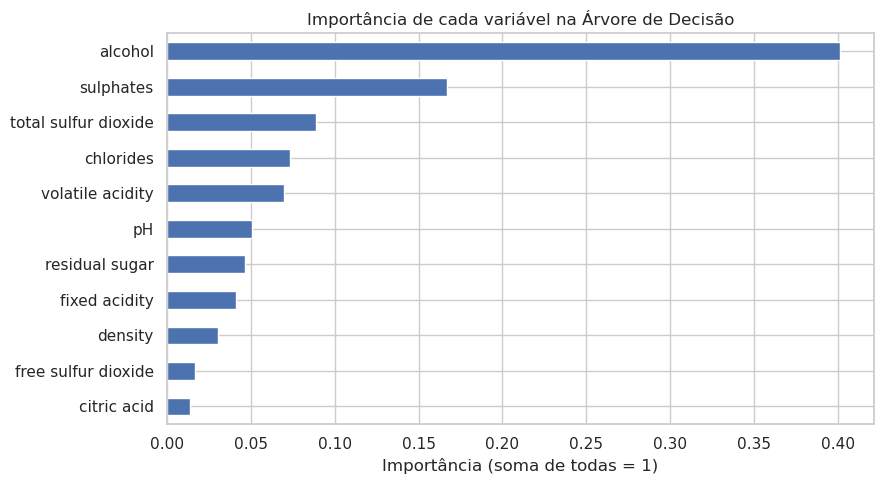

In [48]:
# Quais variáveis a Árvore de Decisão mais usa para decidir?
importancias = pd.Series(arv_final.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(9, 5))
importancias.plot(kind="barh", color="#4c72b0")
plt.title("Importância de cada variável na Árvore de Decisão")
plt.xlabel("Importância (soma de todas = 1)")
plt.tight_layout()
plt.show()

**Leitura:** a árvore se apoia principalmente no **álcool**, na **acidez volátil** e nos **sulfatos** — exatamente as variáveis que a análise exploratória apontou como mais separadoras. O modelo e a estatística clássica contam a mesma história.

In [49]:
# Validação cruzada com 5 pastas: o conjunto é dividido 5 vezes em treino/validação,
# e a métrica final é a média das rodadas — reduz o peso da sorte de uma única divisão.
# Usamos pipelines: o normalizador é reajustado dentro de cada pasta (sem vazamento).
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

pipe_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=melhor_k))
pipe_arv = make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=melhor_prof, random_state=RANDOM_STATE))

cv_knn = cross_val_score(pipe_knn, X, y, cv=cv, scoring="accuracy")
cv_arv = cross_val_score(pipe_arv, X, y, cv=cv, scoring="accuracy")

print(f"KNN    | pastas: {np.round(cv_knn, 3)} | média: {cv_knn.mean():.1%}")
print(f"Árvore | pastas: {np.round(cv_arv, 3)} | média: {cv_arv.mean():.1%}")

KNN    | pastas: [0.725 0.725 0.709 0.75  0.721] | média: 72.6%
Árvore | pastas: [0.706 0.766 0.734 0.753 0.639] | média: 72.0%


**Leitura:** as médias da validação cruzada (72,6% e 72,0%) ficam abaixo dos resultados do teste único (78,4% e 75,3%) — a divisão 80/20 específica foi um pouco generosa — mas a ordem se mantém: KNN à frente da árvore em todas as pastas de forma consistente. Os resultados não dependem de uma divisão de sorte.

---

## ETAPA 4 — Redes Neurais Artificiais: MLP (2,5 pontos)

> **Questão 4.1:** Projete, treine e avalie uma rede neural MLP (Multilayer Perceptron) utilizando a biblioteca Scikit-Learn (`MLPClassifier`) para classificar a qualidade do vinho. Experimente com pelo menos duas arquiteturas de camadas ocultas distintas e descreva qual obteve melhor convergência.

In [50]:
# Três arquiteturas: de 1 camada rasa a 3 camadas mais largas
arquiteturas = {
    "1 camada (8)": (8,),
    "2 camadas (16, 8)": (16, 8),
    "3 camadas (32, 16, 8)": (32, 16, 8),
}

mlps = {}
for nome, camadas in arquiteturas.items():
    mlp = MLPClassifier(
        hidden_layer_sizes=camadas,
        activation="relu",
        solver="adam",
        max_iter=1500,
        random_state=RANDOM_STATE,
    )
    mlp.fit(X_train_scaled, y_train)
    mlps[nome] = mlp
    print(f"{nome:<20} parou após {mlp.n_iter_} épocas")

1 camada (8)         parou após 322 épocas
2 camadas (16, 8)    parou após 1245 épocas
3 camadas (32, 16, 8) parou após 733 épocas


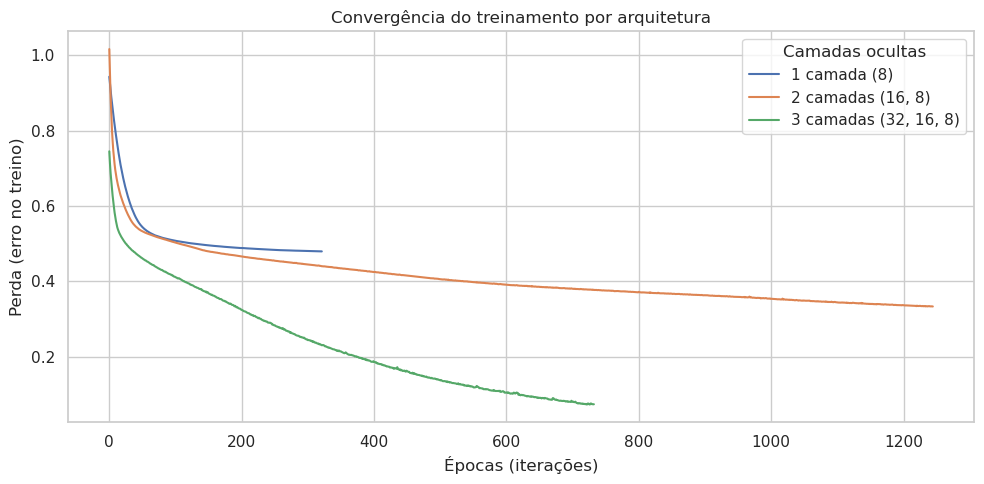

In [51]:
# Curva de perda: como o erro cai a cada época de treino, por arquitetura
plt.figure(figsize=(10, 5))
for nome, mlp in mlps.items():
    plt.plot(mlp.loss_curve_, label=nome)

plt.title("Convergência do treinamento por arquitetura")
plt.xlabel("Épocas (iterações)")
plt.ylabel("Perda (erro no treino)")
plt.legend(title="Camadas ocultas")
plt.tight_layout()
plt.show()

**Leitura:** todas as redes partem de perda parecida (≈0,69, equivalente a chutar aleatoriamente) e caem rápido no início, desacelerando depois. A rede de 1 camada parou primeiro (322 épocas), a de 2 camadas precisou de muito mais treino (1.245 épocas) e a de 3 camadas ficou no meio (733). Mais camadas não significou convergência mais rápida: derivação do gradiente e ponto de parada variam bastante entre arquiteturas.

In [52]:
# Desempenho treino x teste: gap grande entre os dois = sobreajuste (memorização)
linhas = []
for nome, mlp in mlps.items():
    linhas.append({
        "Arquitetura": nome,
        "Acurácia treino": mlp.score(X_train_scaled, y_train),
        "Acurácia teste": mlp.score(X_test_scaled, y_test),
        "Épocas": mlp.n_iter_,
        "Diferença (sobreajuste)": mlp.score(X_train_scaled, y_train) - mlp.score(X_test_scaled, y_test),
    })

tabela_mlp = pd.DataFrame(linhas).set_index("Arquitetura")
tabela_mlp.round(4)

,Acurácia treino,Acurácia teste,Épocas,Diferença (sobreajuste)
Arquitetura,,,,
1 camada (8),0.7568,0.7625,322,-0.0057
"2 camadas (16, 8)",0.8608,0.7906,1245,0.0702
"3 camadas (32, 16, 8)",0.9859,0.7906,733,0.1953


**Leitura:** cada arquitetura conta uma história diferente. A de **1 camada** ajusta de menos: menor acurácia de teste (76,3%) e diferença quase nula entre treino e teste. A de **2 camadas (16, 8)** é o melhor equilíbrio: maior acurácia de teste (79,1%) com sobreajuste pequeno (7 pontos). A de **3 camadas** mostra sobreajuste claro: quase 99% de acerto no treino contra 79,1% no teste — ela decorou os exemplos. Como 2 e 3 camadas empatam no teste, **ficamos com a de 2 camadas, a mais simples**.

Melhor arquitetura: 2 camadas (16, 8)

              precision    recall  f1-score   support

        ruim       0.75      0.83      0.79       149
         bom       0.84      0.75      0.79       171

    accuracy                           0.79       320
   macro avg       0.79      0.79      0.79       320
weighted avg       0.80      0.79      0.79       320



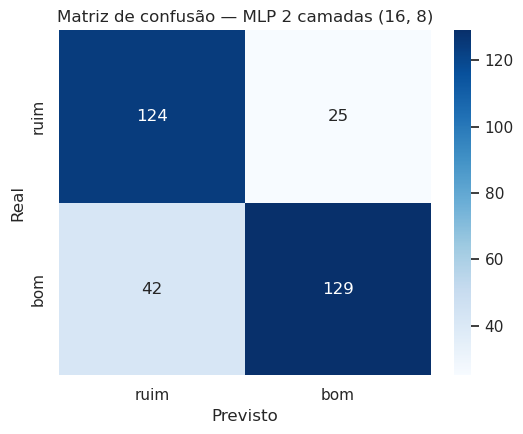

In [53]:
# Melhor arquitetura: relatório e matriz de confusão
melhor_nome = tabela_mlp["Acurácia teste"].idxmax()
mlp_final = mlps[melhor_nome]
pred_mlp = mlp_final.predict(X_test_scaled)

print(f"Melhor arquitetura: {melhor_nome}\n")
print(classification_report(y_test, pred_mlp, labels=["ruim", "bom"]))

plt.figure(figsize=(5.5, 4.5))
cm = confusion_matrix(y_test, pred_mlp, labels=["ruim", "bom"])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["ruim", "bom"], yticklabels=["ruim", "bom"])
plt.title(f"Matriz de confusão — MLP {melhor_nome}")
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.tight_layout()
plt.show()

**Leitura:** a MLP de 2 camadas equilibra melhor os dois tipos de erro (recall 0,83 para 'ruim' e precisão 0,84 para 'bom') e supera levemente o KNN e a árvore em acurácia, sem cair no sobreajuste da versão de 3 camadas.

---

## Conclusão

Para fechar, comparamos os três modelos no mesmo conjunto de teste e com validação cruzada.

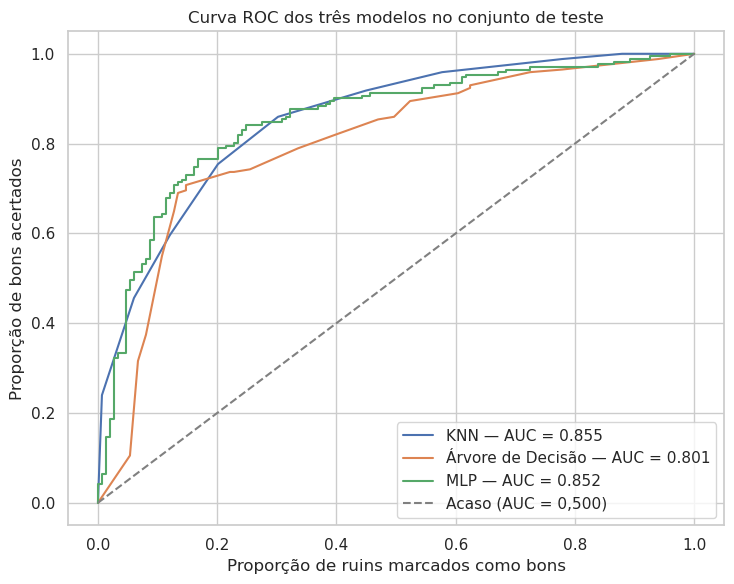

In [54]:
# Curva ROC: trade-off entre acertar os bons e marcar ruins como bons.
# Quanto mais a curva se aproxima do canto superior esquerdo, melhor o modelo.
modelos = {"KNN": knn_final, "Árvore de Decisão": arv_final, "MLP": mlp_final}
auc_por_modelo = {}

plt.figure(figsize=(7.5, 6))
for nome, modelo in modelos.items():
    coluna_bom = list(modelo.classes_).index("bom")
    prob_bom = modelo.predict_proba(X_test_scaled)[:, coluna_bom]
    fpr, tpr, _ = roc_curve(y_test, prob_bom, pos_label="bom")
    auc_por_modelo[nome] = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{nome} — AUC = {auc_por_modelo[nome]:.3f}")

plt.plot([0, 1], [0, 1], "--", color="gray", label="Acaso (AUC = 0,500)")
plt.title("Curva ROC dos três modelos no conjunto de teste")
plt.xlabel("Proporção de ruins marcados como bons")
plt.ylabel("Proporção de bons acertados")
plt.legend()
plt.tight_layout()
plt.show()

**Leitura:** todas as curvas ficam bem acima da linha do acaso (AUC > 0,7), ou seja, os três modelos têm poder real de discriminação. A área sob a curva (AUC) resume cada curva em um número só.

In [55]:
# Tabela final: teste, validação cruzada (5 pastas) e AUC
acuracias_teste = {n: accuracy_score(y_test, m.predict(X_test_scaled)) for n, m in modelos.items()}

cv_mlp = cross_val_score(
    make_pipeline(StandardScaler(), MLPClassifier(
        hidden_layer_sizes=arquiteturas[melhor_nome], max_iter=1500, random_state=RANDOM_STATE)),
    X, y, cv=cv, scoring="accuracy",
)

resumo_final = pd.DataFrame({
    "Acurácia (teste)": acuracias_teste,
    "Acurácia (validação cruzada)": {"KNN": cv_knn.mean(), "Árvore de Decisão": cv_arv.mean(), "MLP": cv_mlp.mean()},
    "AUC (teste)": auc_por_modelo,
})
resumo_final.index.name = "Modelo"
resumo_final.style.format("{:.1%}").highlight_max(axis=0, color="#c6efce")

,Acurácia (teste),Acurácia (validação cruzada),AUC (teste)
Modelo,,,
KNN,78.4%,72.6%,85.5%
Árvore de Decisão,75.3%,72.0%,80.1%
MLP,79.1%,75.4%,85.2%


## Resposta final

- **Etapa 1:** o dataset não tem falhas (sem faltantes, faixas coerentes); o alvo binário ficou equilibrado (53,5% bom x 46,5% ruim) e a normalização colocou as 11 variáveis na mesma escala.
- **Etapa 2:** Cotovelo e Silhueta apontaram **K = 2**. Os agrupamentos se alinham às classes reais só em parte (acordo de 58,7%) — a química separa grupos, mas não reproduz a nota dos degustadores.
- **Etapa 3:** KNN (k = 9) e Árvore (profundidade 6) ficaram próximos, com vantagem para o KNN (78,4% x 75,3% no teste). A validação cruzada confirmou a ordem entre eles.
- **Etapa 4:** das três arquiteturas, **2 camadas ocultas (16, 8)** deu o melhor resultado (79,1% no teste), com sobreajuste pequeno — a de 3 camadas decorou o treino e a de 1 ajustou de menos.

**Qual modelo escolheríamos?** A tabela acima resume: a **MLP** tem a melhor acurácia de teste (79,1%) e a melhor validação cruzada (75,4%), enquanto o **KNN** lidera no AUC por diferença desprezível (0,855 x 0,852). Na prática, escolheríamos a MLP de 2 camadas: é o melhor no critério mais confiável (validação cruzada) e mantém os dois tipos de erro equilibrados. O ganho, porém, é pequeno — e o que os três modelos concordam é o que mais importa: **álcool alto, pouca acidez volátil e mais sulfatos caracterizam os vinhos bons**, o mesmo padrão da análise exploratória.